# Regresión Lineal Múltiple

In [16]:
# librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

## Leer la base de datos

In [17]:
datos = pd.read_excel("/content/drive/MyDrive/MA1031.317FJ/datos_ventas_limpios(1).xlsx")
datos

,Television,Radio,Periodico,Ventas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


## Correlación

In [18]:
# Correlación
datos.corr()

,Television,Radio,Periodico,Ventas
Television,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Periodico,0.056648,0.354104,1.000000,0.228299
Ventas,0.782224,0.576223,0.228299,1.000000


## Modelo de regresión

In [19]:
modelo = smf.ols(formula='Ventas~Television+Radio+Periodico', data=datos)
modelo = modelo.fit()
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Ventas   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Thu, 21 May 2026   Prob (F-statistic):           1.58e-96
Time:                        15:26:11   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.000       2.324       3.554
Television     0.0458      0.001     32.809      0.000       0.043       0.049
Radio          0.1885      0.009     21.893      0.000       0.172       0.206
Periodico     -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Limpieza de variables


In [20]:
modelo = smf.ols(formula='Ventas~Television+Radio', data=datos)
modelo = modelo.fit()
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Ventas   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     859.6
Date:                Thu, 21 May 2026   Prob (F-statistic):           4.83e-98
Time:                        15:30:13   Log-Likelihood:                -386.20
No. Observations:                 200   AIC:                             778.4
Df Residuals:                     197   BIC:                             788.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9211      0.294      9.919      0.000       2.340       3.502
Television     0.0458      0.001     32.909      0.000       0.043       0.048
Radio          0.1880      0.008     23.382      0.000       0.172       0.204
==============================================================================
Omnibus:                       60.022   Durbin-Watson:                   2.081
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              148.679
Skew:                          -1.323   Prob(JB):                     5.19e-33
Kurtosis:                       6.292   Cond. No.                         425.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Ecuación de regresión

In [21]:
y_aprox = 2.9211 + 0.0458*datos['Television'] + 0.1880*datos['Radio']
print(y_aprox)

0      20.56608
1      12.34760
2      12.33806
3      17.62420
4      13.23214
         ...   
195     5.36626
196     8.15666
197    12.77610
198    23.80598
199    15.16808
Length: 200, dtype: float64


## Datos

In [22]:
datos['Ventas']

,Ventas
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9
...,...
195,7.6
196,9.7
197,12.8
198,25.5


## Errores

In [26]:
errores = datos['Ventas'] - y_aprox
print(errores)

0      1.53392
1     -1.94760
2     -3.03806
3      0.87580
4     -0.33214
        ...   
195    2.23374
196    1.54334
197    0.02390
198    1.69402
199   -1.76808
Length: 200, dtype: float64


## Gráfico

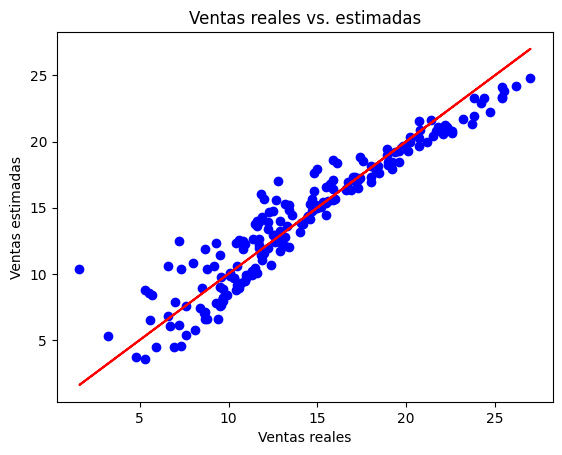

In [28]:
plt.scatter(datos['Ventas'], y_aprox, color = 'blue')
plt.plot(datos['Ventas'], datos['Ventas'], color = 'red')
plt.xlabel('Ventas reales')
plt.ylabel('Ventas estimadas')
plt.title('Ventas reales vs. estimadas')
plt.show()

## Graficar errores

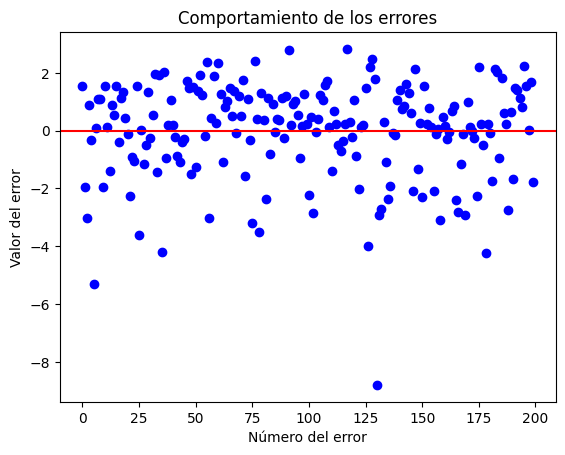

In [30]:
plt.scatter(range(200), errores, color = 'blue')
plt.axhline(y=0, color='red')
plt.xlabel('Número del error')
plt.ylabel('Valor del error')
plt.title('Comportamiento de los errores')
plt.show()

## Histograma de los errores

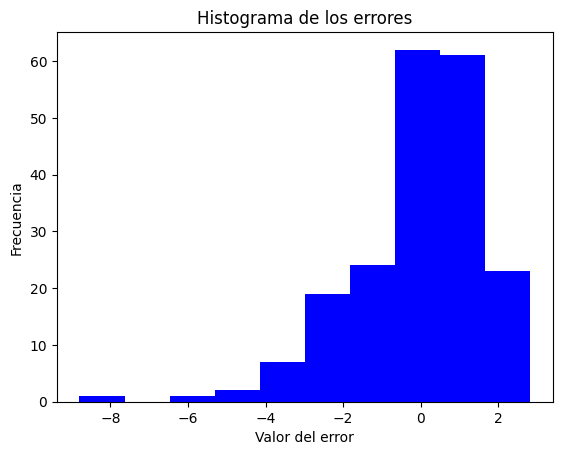

In [31]:
plt.hist(errores, color = 'blue')
plt.xlabel('Valor del error')
plt.ylabel('Frecuencia')
plt.title('Histograma de los errores')
plt.show()